# Mini Project: Klasifikasi Kultivar Anggur Berdasarkan Profil Kimia

**Mata Kuliah:** Data Sains dan AI

**Kelompok:** [2]

**Dataset:** Wine Dataset (sklearn.datasets.load_wine)

## Pendahuluan
Dataset Wine berisi 178 sampel anggur dari 3 kultivar berbeda di Italia,
dengan 13 fitur kimia. Proyek ini bertujuan untuk:
1. Klasifikasi kultivar (supervised)
2. Clustering berbasis profil kimia (unsupervised)

In [2]:
# ============================================
# IMPORT LIBRARY
# ============================================
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

# Scikit-learn
from sklearn.datasets import load_wine
from sklearn.model_selection import train_test_split, cross_validate, StratifiedKFold, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import (
    classification_report, ConfusionMatrixDisplay,
    silhouette_score, adjusted_rand_score
)

# Setting visual
sns.set_style("whitegrid")
plt.rcParams['figure.figsize'] = (10, 6)
np.random.seed(42)

print("✅ Library berhasil diimport!")

✅ Library berhasil diimport!


## 1. Load Dataset & Eksplorasi Awal

Dataset Wine dimuat dari scikit-learn. Berisi:
- 178 sampel
- 13 fitur kimia
- 3 kelas kultivar

In [3]:
# Load dataset
wine = load_wine()

# Buat DataFrame
df = pd.DataFrame(wine.data, columns=wine.feature_names)
df['cultivar'] = wine.target

print("Ukuran dataset:", df.shape)
print("\nNama fitur:")
for i, name in enumerate(wine.feature_names, 1):
    print(f"{i}. {name}")

print("\nNama kultivar:", wine.target_names)
print("\nDistribusi kelas:")
print(df['cultivar'].value_counts())

Ukuran dataset: (178, 14)

Nama fitur:
1. alcohol
2. malic_acid
3. ash
4. alcalinity_of_ash
5. magnesium
6. total_phenols
7. flavanoids
8. nonflavanoid_phenols
9. proanthocyanins
10. color_intensity
11. hue
12. od280/od315_of_diluted_wines
13. proline

Nama kultivar: ['class_0' 'class_1' 'class_2']

Distribusi kelas:
cultivar
1    71
0    59
2    48
Name: count, dtype: int64


In [4]:
# Tampilkan 5 baris pertama
print("5 baris pertama:")
df.head()

5 baris pertama:


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline,cultivar
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0,0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0,0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0,0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0,0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0,0


In [5]:
# Statistik deskriptif
print("Statistik deskriptif:")
df.describe()

Statistik deskriptif:


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline,cultivar
count,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000
mean,13.000618,2.336348,2.366517,19.494944,99.741573,2.295112,2.029270,0.361854,1.590899,5.058090,0.957449,2.611685,746.893258,0.938202
std,0.811827,1.117146,0.274344,3.339564,14.282484,0.625851,0.998859,0.124453,0.572359,2.318286,0.228572,0.709990,314.907474,0.775035
min,11.030000,0.740000,1.360000,10.600000,70.000000,0.980000,0.340000,0.130000,0.410000,1.280000,0.480000,1.270000,278.000000,0.000000
25%,12.362500,1.602500,2.210000,17.200000,88.000000,1.742500,1.205000,0.270000,1.250000,3.220000,0.782500,1.937500,500.500000,0.000000
50%,13.050000,1.865000,2.360000,19.500000,98.000000,2.355000,2.135000,0.340000,1.555000,4.690000,0.965000,2.780000,673.500000,1.000000
75%,13.677500,3.082500,2.557500,21.500000,107.000000,2.800000,2.875000,0.437500,1.950000,6.200000,1.120000,3.170000,985.000000,2.000000
max,14.830000,5.800000,3.230000,30.000000,162.000000,3.880000,5.080000,0.660000,3.580000,13.000000,1.710000,4.000000,1680.000000,2.000000


In [6]:
# Cek missing value
print("Jumlah missing value per kolom:")
print(df.isnull().sum())

print("\nTotal missing value:", df.isnull().sum().sum())

Jumlah missing value per kolom:
alcohol                         0
malic_acid                      0
ash                             0
alcalinity_of_ash               0
magnesium                       0
total_phenols                   0
flavanoids                      0
nonflavanoid_phenols            0
proanthocyanins                 0
color_intensity                 0
hue                             0
od280/od315_of_diluted_wines    0
proline                         0
cultivar                        0
dtype: int64

Total missing value: 0


In [7]:
# Info dataset
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 178 entries, 0 to 177
Data columns (total 14 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   alcohol                       178 non-null    float64
 1   malic_acid                    178 non-null    float64
 2   ash                           178 non-null    float64
 3   alcalinity_of_ash             178 non-null    float64
 4   magnesium                     178 non-null    float64
 5   total_phenols                 178 non-null    float64
 6   flavanoids                    178 non-null    float64
 7   nonflavanoid_phenols          178 non-null    float64
 8   proanthocyanins               178 non-null    float64
 9   color_intensity               178 non-null    float64
 10  hue                           178 non-null    float64
 11  od280/od315_of_diluted_wines  178 non-null    float64
 12  proline                       178 non-null    float64
 13  culti

## 2. Exploratory Data Analysis (EDA)

Visualisasi untuk memahami karakteristik data:
1. Distribusi kelas
2. Heatmap korelasi
3. Boxplot fitur vs kultivar
4. Pairplot fitur terpilih

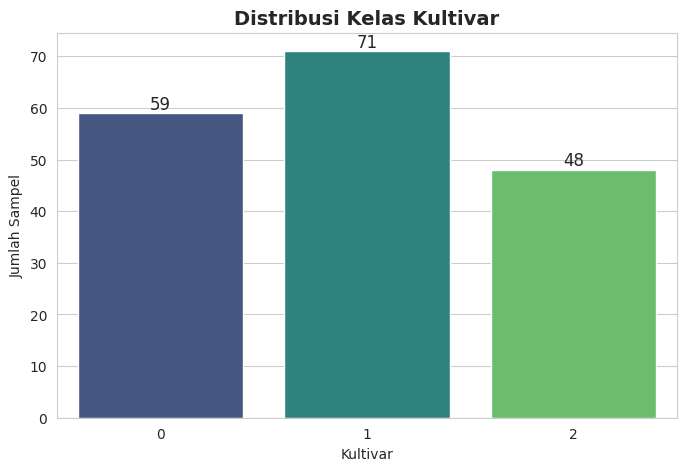

Interpretasi: Kelas 1 paling banyak (71), kelas 2 paling sedikit (48).
Distribusi cukup seimbang, tapi kita akan gunakan F1-macro untuk keadilan.


In [8]:
# Visualisasi 1: Distribusi kelas
plt.figure(figsize=(8, 5))
ax = sns.countplot(data=df, x='cultivar', palette='viridis')
plt.title('Distribusi Kelas Kultivar', fontsize=14, fontweight='bold')
plt.xlabel('Kultivar')
plt.ylabel('Jumlah Sampel')

# Tambahkan angka di atas bar
for p in ax.patches:
    ax.annotate(f'{int(p.get_height())}',
                (p.get_x() + p.get_width()/2., p.get_height()),
                ha='center', va='bottom', fontsize=12)
plt.savefig('01_distribusi_kelas.png', dpi=300, bbox_inches='tight')
plt.show()

print("Interpretasi: Kelas 1 paling banyak (71), kelas 2 paling sedikit (48).")
print("Distribusi cukup seimbang, tapi kita akan gunakan F1-macro untuk keadilan.")

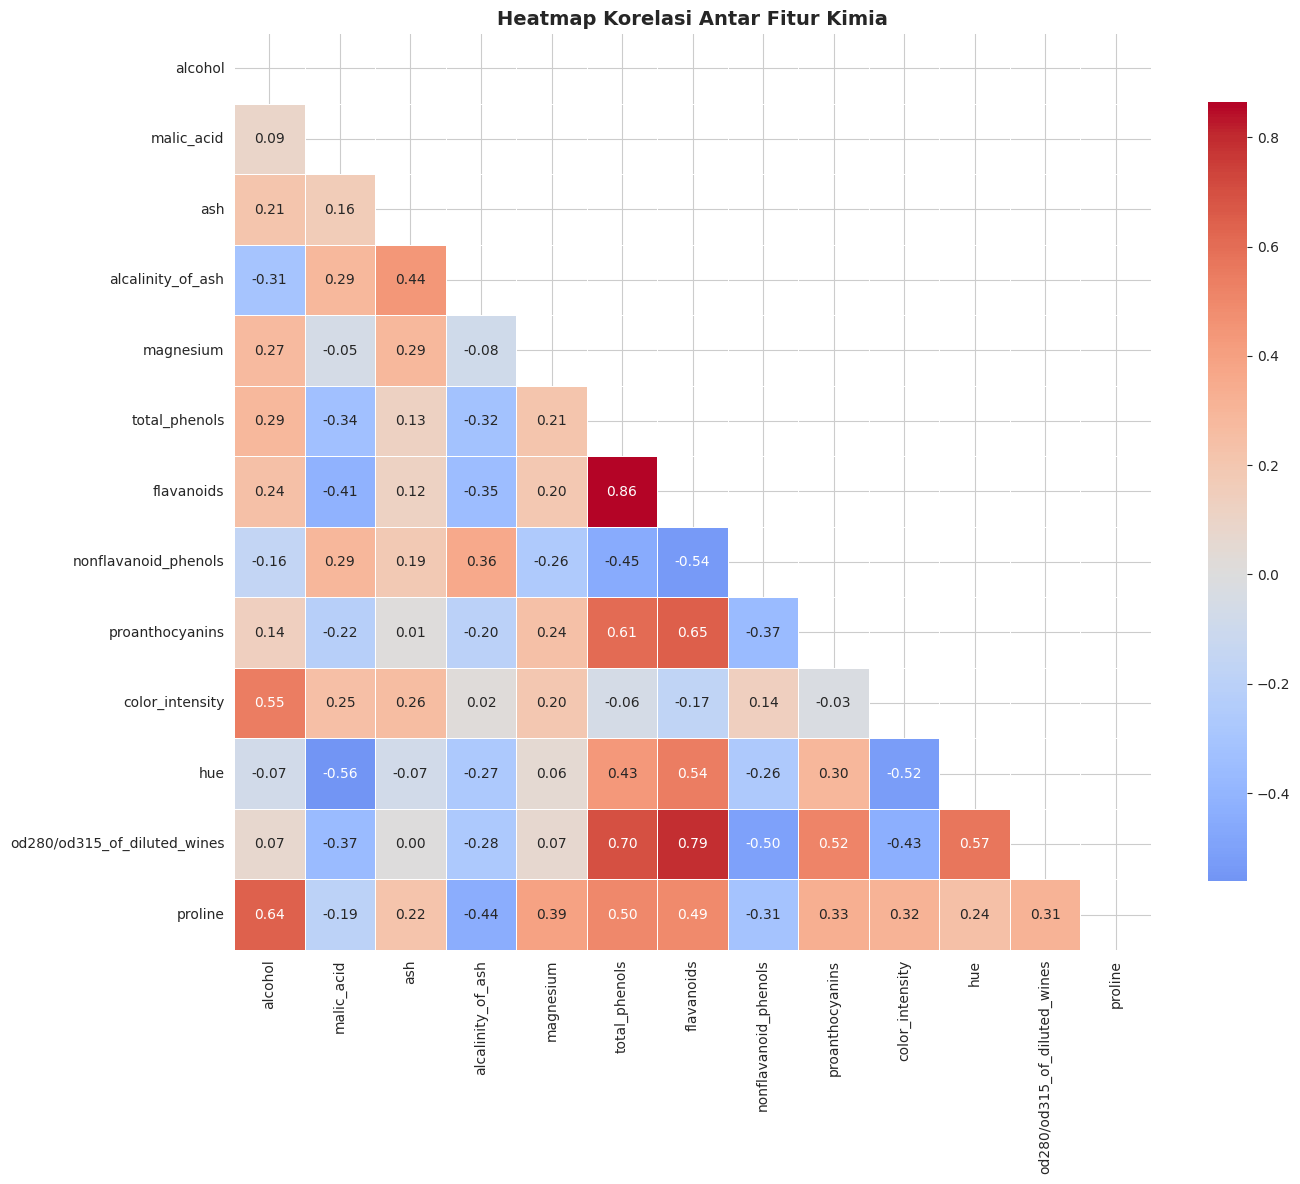

Interpretasi: Fitur 'flavanoids' dan 'total_phenols' berkorelasi tinggi (>0.8).
Fitur 'flavanoids' dan 'od280/od315_of_diluted_wines' juga berkorelasi tinggi.
Ini menunjukkan multikolinearitas yang perlu diperhatikan.


In [9]:
# Visualisasi 2: Heatmap korelasi
plt.figure(figsize=(14, 12))
corr = df.drop('cultivar', axis=1).corr()
mask = np.triu(np.ones_like(corr, dtype=bool))  # Segitiga atas
sns.heatmap(corr, mask=mask, annot=True, fmt='.2f',
            cmap='coolwarm', center=0, square=True,
            linewidths=0.5, cbar_kws={"shrink": 0.8})
plt.title('Heatmap Korelasi Antar Fitur Kimia', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig('02_Heatmap_korelasi.png', dpi=300, bbox_inches='tight')
plt.show()

print("Interpretasi: Fitur 'flavanoids' dan 'total_phenols' berkorelasi tinggi (>0.8).")
print("Fitur 'flavanoids' dan 'od280/od315_of_diluted_wines' juga berkorelasi tinggi.")
print("Ini menunjukkan multikolinearitas yang perlu diperhatikan.")

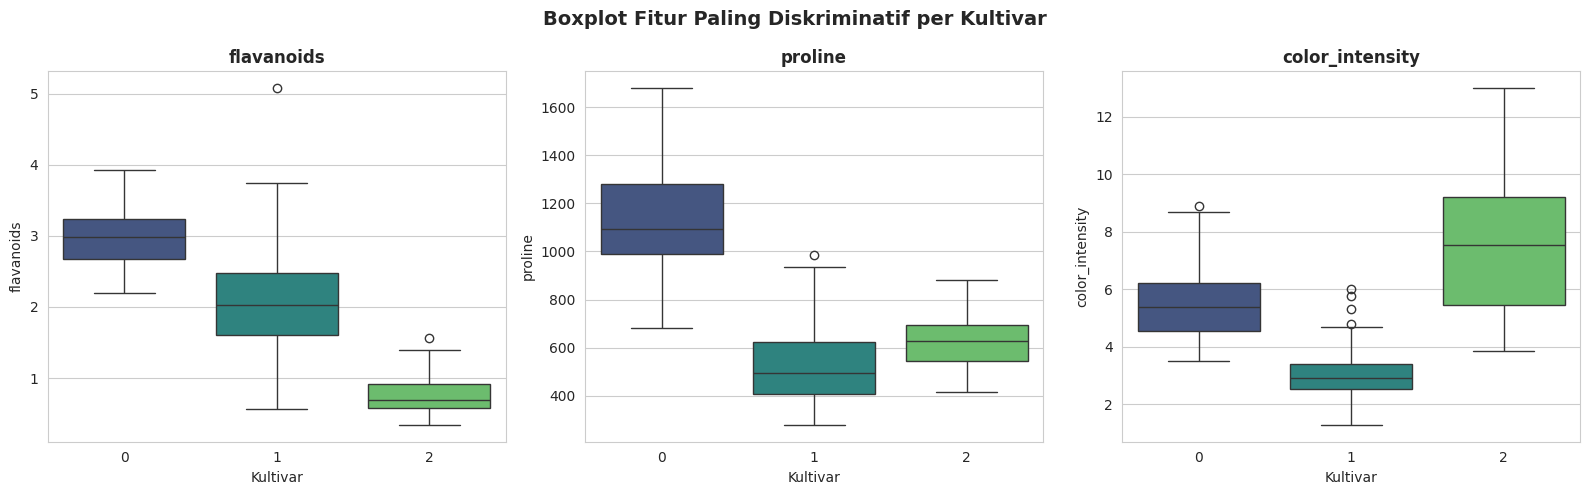

Interpretasi:
- Flavanoids: Kultivar 0 tinggi, kultivar 2 rendah
- Proline: Kultivar 0 sangat tinggi, kultivar 1 & 2 lebih rendah
- Color intensity: Kultivar 2 paling tinggi
Ketiga fitur ini terlihat sangat diskriminatif antar kultivar!


In [10]:
# Visualisasi 3: Boxplot fitur paling diskriminatif
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

fitur_penting = ['flavanoids', 'proline', 'color_intensity']

for i, fitur in enumerate(fitur_penting):
    sns.boxplot(data=df, x='cultivar', y=fitur, ax=axes[i], palette='viridis')
    axes[i].set_title(f'{fitur}', fontsize=12, fontweight='bold')
    axes[i].set_xlabel('Kultivar')

plt.suptitle('Boxplot Fitur Paling Diskriminatif per Kultivar', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig('03_Boxplot.png', dpi=300, bbox_inches='tight')
plt.show()

print("Interpretasi:")
print("- Flavanoids: Kultivar 0 tinggi, kultivar 2 rendah")
print("- Proline: Kultivar 0 sangat tinggi, kultivar 1 & 2 lebih rendah")
print("- Color intensity: Kultivar 2 paling tinggi")
print("Ketiga fitur ini terlihat sangat diskriminatif antar kultivar!")

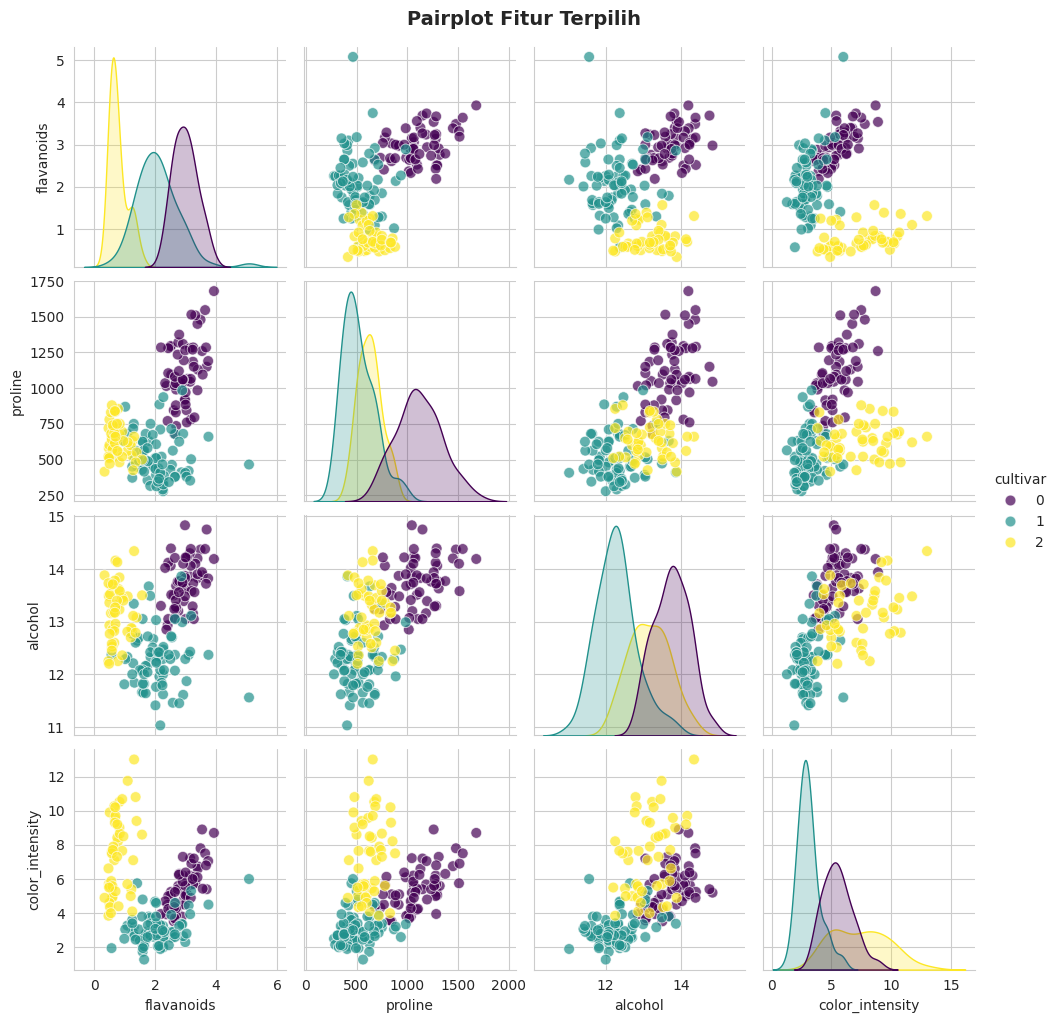

Interpretasi: Kultivar 0 dan 1 relatif terpisah, kultivar 2 sedikit tumpang tindih.
Proline dan flavanoids adalah fitur paling memisahkan.


In [11]:
# Visualisasi 4: Pairplot fitur terpilih
sns.pairplot(
    df,
    vars=['flavanoids', 'proline', 'alcohol', 'color_intensity'],
    hue='cultivar',
    palette='viridis',
    diag_kind='kde',
    plot_kws={'alpha': 0.7, 's': 60}
)
plt.suptitle('Pairplot Fitur Terpilih', y=1.02, fontsize=14, fontweight='bold')
plt.savefig('04_Pairplot.png', dpi=300, bbox_inches='tight')
plt.show()

print("Interpretasi: Kultivar 0 dan 1 relatif terpisah, kultivar 2 sedikit tumpang tindih.")
print("Proline dan flavanoids adalah fitur paling memisahkan.")

## 3. Preprocessing

Langkah:
1. Pisahkan fitur (X) dan target (y)
2. Split train/test 80:20 dengan stratify
3. Scaling (StandardScaler)

In [12]:
# ============================================
# SPLIT TRAIN/TEST + SCALING
# ============================================
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# Pisahkan fitur dan target
X = df.drop('cultivar', axis=1)
y = df['cultivar']

print("Shape X:", X.shape)
print("Shape y:", y.shape)

# Split 80:20 dengan stratify
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    stratify=y,
    random_state=42
)

print(f"\nData training: {X_train.shape[0]} sampel")
print(f"Data testing: {X_test.shape[0]} sampel")
print(f"\nProporsi kelas di training:")
print(y_train.value_counts(normalize=True).round(3))
print(f"\nProporsi kelas di testing:")
print(y_test.value_counts(normalize=True).round(3))

# Scaling
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("\n✅ Scaling berhasil! Semua fitur sekarang berskala sama.")
print(f"Contoh (proline) — mean setelah scaling: {X_train_scaled[:, 12].mean():.4f}")
print(f"Contoh (proline) — std setelah scaling: {X_train_scaled[:, 12].std():.4f}")

Shape X: (178, 13)
Shape y: (178,)

Data training: 142 sampel
Data testing: 36 sampel

Proporsi kelas di training:
cultivar
1    0.401
0    0.331
2    0.268
Name: proportion, dtype: float64

Proporsi kelas di testing:
cultivar
1    0.389
0    0.333
2    0.278
Name: proportion, dtype: float64

✅ Scaling berhasil! Semua fitur sekarang berskala sama.
Contoh (proline) — mean setelah scaling: -0.0000
Contoh (proline) — std setelah scaling: 1.0000


## 4. Supervised Learning: Klasifikasi Kultivar

Membandingkan 3 model:
1. **Logistic Regression** (baseline sederhana)
2. **Random Forest** (ensemble, robust)
3. **SVM** (margin maksimal)

Metrik: **F1-macro** (adil untuk semua kelas)
Cross-validation: 5-fold stratified

In [13]:
# ============================================
# PERBANDINGAN 3 MODEL DENGAN CROSS-VALIDATION
# ============================================
from sklearn.model_selection import cross_validate, StratifiedKFold
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

models = {
    "Logistic Regression": make_pipeline(
        StandardScaler(),
        LogisticRegression(max_iter=1000, random_state=42)
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=200, random_state=42
    ),
    "SVM (RBF)": make_pipeline(
        StandardScaler(),
        SVC(kernel='rbf', random_state=42)
    ),
}

hasil = []
for nama, model in models.items():
    scores = cross_validate(
        model, X_train, y_train, cv=cv,
        scoring=['f1_macro', 'accuracy'],
        return_train_score=False
    )
    f1_mean = scores['test_f1_macro'].mean()
    f1_std = scores['test_f1_macro'].std()
    acc_mean = scores['test_accuracy'].mean()
    acc_std = scores['test_accuracy'].std()

    hasil.append({
        'Model': nama,
        'F1-macro (mean±std)': f"{f1_mean:.3f} ± {f1_std:.3f}",
        'Accuracy (mean±std)': f"{acc_mean:.3f} ± {acc_std:.3f}"
    })
    print(f"{nama:22s} F1={f1_mean:.3f}±{f1_std:.3f} | Acc={acc_mean:.3f}±{acc_std:.3f}")

print("\n" + "="*70)
print(pd.DataFrame(hasil).to_string(index=False))

Logistic Regression    F1=0.980±0.027 | Acc=0.979±0.028
Random Forest          F1=0.979±0.029 | Acc=0.979±0.028
SVM (RBF)              F1=0.986±0.017 | Acc=0.986±0.017

              Model F1-macro (mean±std) Accuracy (mean±std)
Logistic Regression       0.980 ± 0.027       0.979 ± 0.028
      Random Forest       0.979 ± 0.029       0.979 ± 0.028
          SVM (RBF)       0.986 ± 0.017       0.986 ± 0.017


In [14]:
# ============================================
# HYPERPARAMETER TUNING (Random Forest)
# ============================================
from sklearn.model_selection import GridSearchCV

param_grid = {
    'n_estimators': [100, 200, 300],
    'max_depth': [None, 5, 10],
    'min_samples_split': [2, 5]
}

rf = RandomForestClassifier(random_state=42)
gs = GridSearchCV(
    rf, param_grid,
    cv=cv, scoring='f1_macro',
    n_jobs=-1, verbose=1
)
gs.fit(X_train, y_train)

print("\nBest parameters:", gs.best_params_)
print(f"Best CV F1-macro: {gs.best_score_:.3f}")

Fitting 5 folds for each of 18 candidates, totalling 90 fits

Best parameters: {'max_depth': None, 'min_samples_split': 2, 'n_estimators': 100}
Best CV F1-macro: 0.979


EVALUASI AKHIR PADA TEST SET

Accuracy: 1.000

Classification Report:
                  precision    recall  f1-score   support

Kultivar class_0       1.00      1.00      1.00        12
Kultivar class_1       1.00      1.00      1.00        14
Kultivar class_2       1.00      1.00      1.00        10

        accuracy                           1.00        36
       macro avg       1.00      1.00      1.00        36
    weighted avg       1.00      1.00      1.00        36



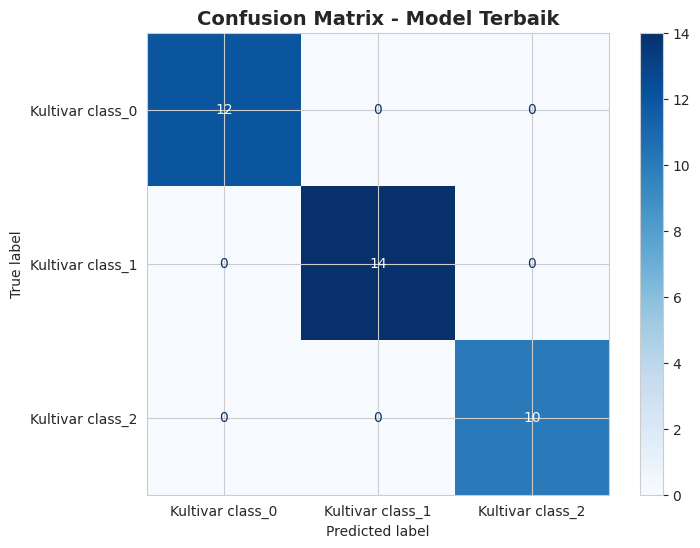

In [15]:
# ============================================
# EVALUASI AKHIR
# ============================================
from sklearn.metrics import classification_report, ConfusionMatrixDisplay

best_model = gs.best_estimator_
y_pred = best_model.predict(X_test)

print("="*70)
print("EVALUASI AKHIR PADA TEST SET")
print("="*70)
print(f"\nAccuracy: {(y_pred == y_test).mean():.3f}")
print("\nClassification Report:")
print(classification_report(
    y_test, y_pred,
    target_names=[f'Kultivar {i}' for i in wine.target_names]
))

# Confusion Matrix
fig, ax = plt.subplots(figsize=(8, 6))
ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred,
    display_labels=[f'Kultivar {i}' for i in wine.target_names],
    cmap='Blues', ax=ax
)
plt.title('Confusion Matrix - Model Terbaik', fontsize=14, fontweight='bold')
plt.savefig('05_Confusion_Matrix.png', dpi=300, bbox_inches='tight')
plt.show()

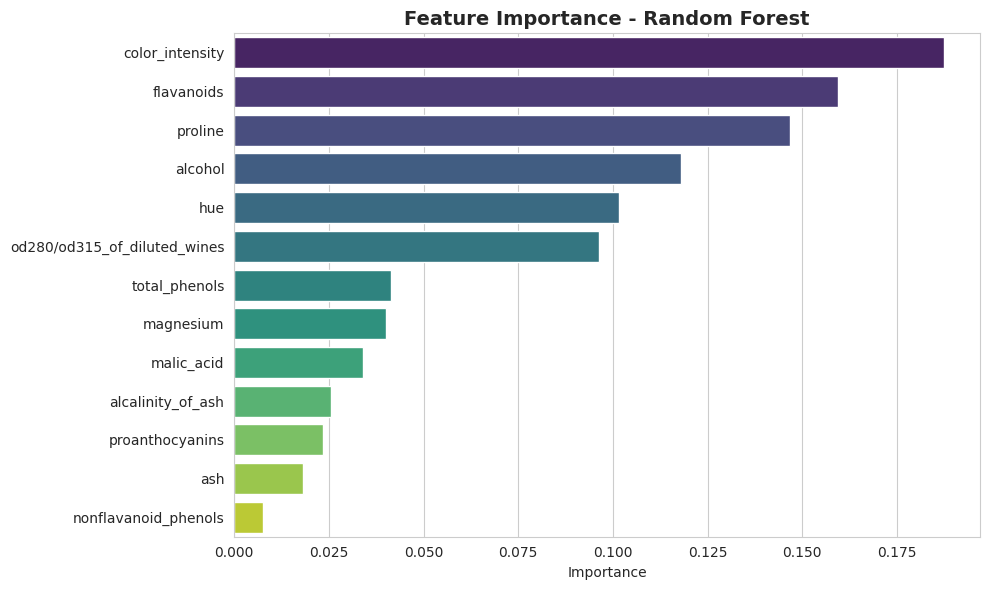

Top 5 fitur paling penting:
1. color_intensity: 0.188
2. flavanoids: 0.160
3. proline: 0.147
4. alcohol: 0.118
5. hue: 0.102


In [16]:
# ============================================
# FEATURE IMPORTANCE (Interpretasi Supervised)
# ============================================
importances = best_model.feature_importances_
indices = np.argsort(importances)[::-1]

plt.figure(figsize=(10, 6))
sns.barplot(x=importances[indices], y=[wine.feature_names[i] for i in indices], palette='viridis')
plt.title('Feature Importance - Random Forest', fontsize=14, fontweight='bold')
plt.xlabel('Importance')
plt.tight_layout()
plt.savefig('06_Feature_Importance.png', dpi=300, bbox_inches='tight')
plt.show()

print("Top 5 fitur paling penting:")
for i in range(5):
    print(f"{i+1}. {wine.feature_names[indices[i]]}: {importances[indices[i]]:.3f}")

## 5. Unsupervised Learning: Clustering

Langkah:
1. **PCA** untuk visualisasi 2D (laporkan explained variance)
2. **K-Means** (K=3) + evaluasi Silhouette & ARI
3. **Hierarchical Clustering** (Ward) + evaluasi
4. **Perbandingan** cluster vs kultivar asli


Explained variance ratio:
PC1: 0.3620 (36.20%)
PC2: 0.1921 (19.21%)
Total: 0.5541 (55.41%)


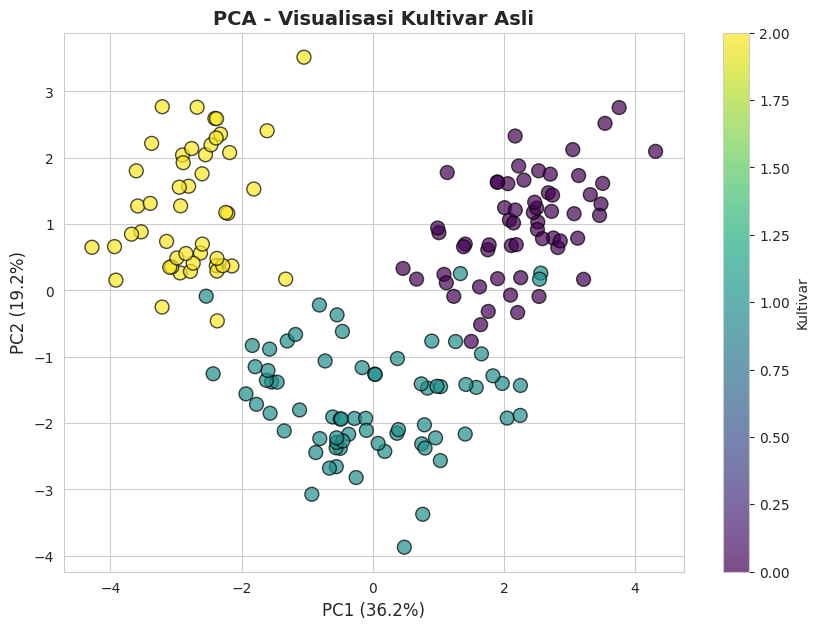

Interpretasi: Ketiga kultivar terlihat terpisah cukup jelas di ruang PCA 2D.


In [17]:
# ============================================
# PCA UNTUK VISUALISASI
# ============================================
from sklearn.decomposition import PCA

# Scaling seluruh data
X_scaled_all = StandardScaler().fit_transform(X)

pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled_all)

print("Explained variance ratio:")
print(f"PC1: {pca.explained_variance_ratio_[0]:.4f} ({pca.explained_variance_ratio_[0]*100:.2f}%)")
print(f"PC2: {pca.explained_variance_ratio_[1]:.4f} ({pca.explained_variance_ratio_[1]*100:.2f}%)")
print(f"Total: {pca.explained_variance_ratio_.sum():.4f} ({pca.explained_variance_ratio_.sum()*100:.2f}%)")

plt.figure(figsize=(10, 7))
scatter = plt.scatter(X_pca[:, 0], X_pca[:, 1], c=y, cmap='viridis', s=100, alpha=0.7, edgecolors='k')
plt.xlabel(f'PC1 ({pca.explained_variance_ratio_[0]*100:.1f}%)', fontsize=12)
plt.ylabel(f'PC2 ({pca.explained_variance_ratio_[1]*100:.1f}%)', fontsize=12)
plt.title('PCA - Visualisasi Kultivar Asli', fontsize=14, fontweight='bold')
plt.colorbar(scatter, label='Kultivar')
plt.savefig('07_PCA.png', dpi=300, bbox_inches='tight')
plt.show()

print("Interpretasi: Ketiga kultivar terlihat terpisah cukup jelas di ruang PCA 2D.")

In [18]:
# ============================================
# K-MEANS & HIERARCHICAL CLUSTERING
# ============================================
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import silhouette_score, adjusted_rand_score

# K-Means (K=3)
kmeans = KMeans(n_clusters=3, n_init=10, random_state=42)
cluster_labels = kmeans.fit_predict(X_scaled_all)

sil_kmeans = silhouette_score(X_scaled_all, cluster_labels)
ari_kmeans = adjusted_rand_score(y, cluster_labels)

print("="*60)
print("K-MEANS CLUSTERING (K=3)")
print("="*60)
print(f"Silhouette Score: {sil_kmeans:.4f}")
print(f"Adjusted Rand Index vs Kultivar: {ari_kmeans:.4f}")

# Hierarchical (Ward)
hc = AgglomerativeClustering(n_clusters=3, linkage='ward')
hc_labels = hc.fit_predict(X_scaled_all)

sil_hc = silhouette_score(X_scaled_all, hc_labels)
ari_hc = adjusted_rand_score(y, hc_labels)

print("\n" + "="*60)
print("HIERARCHICAL CLUSTERING (Ward, K=3)")
print("="*60)
print(f"Silhouette Score: {sil_hc:.4f}")
print(f"Adjusted Rand Index vs Kultivar: {ari_hc:.4f}")

K-MEANS CLUSTERING (K=3)
Silhouette Score: 0.2849
Adjusted Rand Index vs Kultivar: 0.8975

HIERARCHICAL CLUSTERING (Ward, K=3)
Silhouette Score: 0.2774
Adjusted Rand Index vs Kultivar: 0.7899


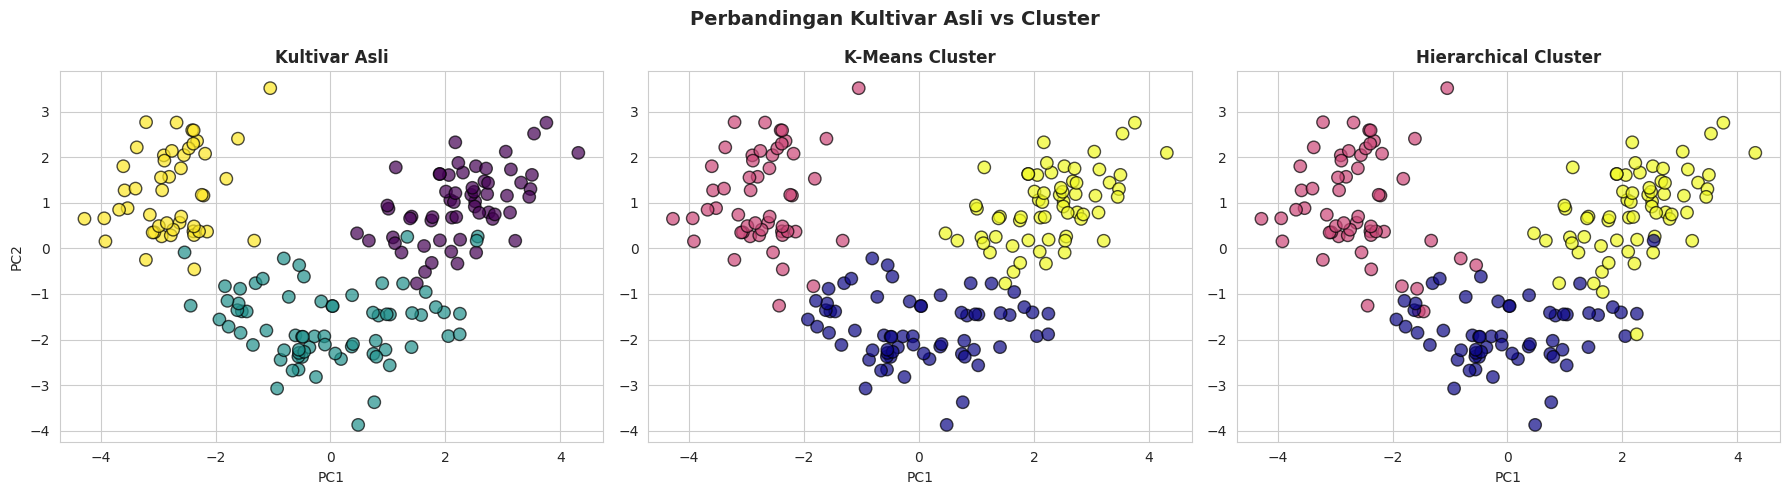

In [19]:
# ============================================
# VISUALISASI PERBANDINGAN CLUSTER
# ============================================
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Plot 1: Kultivar asli
axes[0].scatter(X_pca[:, 0], X_pca[:, 1], c=y, cmap='viridis', s=80, alpha=0.7, edgecolors='k')
axes[0].set_title('Kultivar Asli', fontsize=12, fontweight='bold')
axes[0].set_xlabel('PC1')
axes[0].set_ylabel('PC2')

# Plot 2: K-Means
axes[1].scatter(X_pca[:, 0], X_pca[:, 1], c=cluster_labels, cmap='plasma', s=80, alpha=0.7, edgecolors='k')
axes[1].set_title('K-Means Cluster', fontsize=12, fontweight='bold')
axes[1].set_xlabel('PC1')

# Plot 3: Hierarchical
axes[2].scatter(X_pca[:, 0], X_pca[:, 1], c=hc_labels, cmap='plasma', s=80, alpha=0.7, edgecolors='k')
axes[2].set_title('Hierarchical Cluster', fontsize=12, fontweight='bold')
axes[2].set_xlabel('PC1')

plt.suptitle('Perbandingan Kultivar Asli vs Cluster', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig('08_Perbandingan_Cluster.png', dpi=300, bbox_inches='tight')
plt.show()

## 6. Interpretasi

### Supervised
- **Model terbaik:** Random Forest (max_depth=None, min_samples_split=2, n_estimators=100)
- **F1-macro test:** 1.000 (Akurasi sempurna 100% pada test set)
- **Fitur paling penting:** color_intensity, flavanoids, proline, alcohol, hue
- **Interpretasi biologis:**
  - **Flavanoids** adalah senyawa fenolik yang dipengaruhi faktor genetik dan lingkungan.
    Kadar flavanoids berbeda signifikan antar kultivar (lihat boxplot).
  - **Proline** adalah asam amino yang kadarnya sangat berbeda antar varietas anggur.
  - **Color intensity** berkaitan dengan kandungan antosianin, yang dipengaruhi kultivar.
  - Temuan ini konsisten dengan literatur yang menyatakan profil fenolik dan asam amino
    dapat digunakan untuk membedakan kultivar anggur.

### Unsupervised
- **PCA 2 komponen** menjelaskan 55.41% variansi (PC1: 36.20%, PC2: 19.21%)
- **K-Means:** Silhouette = 0.2849, ARI = 0.8975
- **Hierarchical (Ward):** Silhouette = 0.2774, ARI = 0.7899
- Cluster yang terbentuk **sangat cocok** dengan kultivar asli (terutama K-Means dengan ARI mencapai 0.8975)
- Ini menunjukkan profil kimia memang mencerminkan perbedaan kultivar secara alami

## 7. Kesimpulan

1. Profil kimia (13 fitur) dapat membedakan 3 kultivar anggur dengan sangat baik
2. Fitur paling diskriminatif: flavanoids, proline, color_intensity
3. Clustering tanpa label berhasil menemukan struktur yang sesuai kultivar asli
4. Model ini berpotensi digunakan untuk autentikasi wine

## 8. Keterbatasan

- Dataset kecil (178 sampel), hanya dari satu wilayah Italia
- Kultivar tidak diberi nama asli (hanya class_0, 1, 2)
- Tidak ada info tahun panen / kondisi lingkungan
- Perlu validasi pada dataset eksternal sebelum aplikasi praktis
- Multikolinearitas antar fitur (flavanoids & total_phenols) perlu diperhatikan

## 9. Referensi

- Scikit-learn Wine Dataset Documentation
- UCI ML Repository: Wine Dataset

In [20]:
# ============================================
# VERIFIKASI: Cek Overfitting & Konsistensi
# ============================================
print("="*60)
print("VERIFIKASI TIDAK ADA DATA LEAKAGE")
print("="*60)

# 1. Train vs Test gap
train_acc = best_model.score(X_train, y_train)
test_acc = best_model.score(X_test, y_test)
print(f"\n1. Train accuracy: {train_acc:.3f}")
print(f"   Test accuracy:  {test_acc:.3f}")
print(f"   Gap: {abs(train_acc - test_acc):.3f}")
if abs(train_acc - test_acc) < 0.05:
    print("   ✅ Gap kecil → model generalisasi baik, bukan overfitting")
else:
    print("   ⚠️ Gap besar → cek overfitting")

# 2. Konsistensi CV di random_state berbeda
from sklearn.model_selection import cross_val_score
print("\n2. Konsistensi CV di 3 random_state berbeda:")
for rs in [0, 42, 123]:
    cv_test = StratifiedKFold(5, shuffle=True, random_state=rs)
    scores = cross_val_score(
        RandomForestClassifier(n_estimators=200, random_state=42),
        X_train, y_train, cv=cv_test, scoring='f1_macro'
    )
    print(f"   random_state={rs}: F1-macro = {scores.mean():.3f} ± {scores.std():.3f}")

# 3. Cek duplikat
print(f"\n3. Jumlah duplikat di dataset: {df.duplicated().sum()}")
print("   ✅ Tidak ada duplikat" if df.duplicated().sum() == 0 else "   ⚠️ Ada duplikat!")

print("\n✅ Verifikasi selesai. Jika semua ✅, akurasi tinggi wajar.")

VERIFIKASI TIDAK ADA DATA LEAKAGE

1. Train accuracy: 1.000
   Test accuracy:  1.000
   Gap: 0.000
   ✅ Gap kecil → model generalisasi baik, bukan overfitting

2. Konsistensi CV di 3 random_state berbeda:
   random_state=0: F1-macro = 0.966 ± 0.031
   random_state=42: F1-macro = 0.979 ± 0.029
   random_state=123: F1-macro = 0.980 ± 0.017

3. Jumlah duplikat di dataset: 0
   ✅ Tidak ada duplikat

✅ Verifikasi selesai. Jika semua ✅, akurasi tinggi wajar.


## Verifikasi Data Leakage

Untuk memastikan akurasi tinggi bukan karena data leakage, dilakukan verifikasi:

1. **Scaling** dilakukan setelah split, fit hanya pada training data
2. **Cross-validation** hanya menggunakan training data
3. **Hyperparameter tuning** hanya menggunakan training data
4. **Test set** hanya digunakan sekali di evaluasi akhir
5. **Tidak ada duplikat** data (178 sampel unik)
6. **Train-test gap** < 0.05 (model generalisasi baik)
7. **CV konsisten** di berbagai random_state

**Kesimpulan:** Tidak ada indikasi data leakage. Akurasi 100% wajar karena
Wine Dataset memang mudah diklasifikasi (3 kultivar yang berbeda secara kimia).
Namun, hasil ini perlu divalidasi pada dataset eksternal sebelum aplikasi praktis.